In [1]:
import pandas as pd, numpy as np

In [2]:
df = pd.read_csv("../data/raw/transactions.csv")
df.head()

,user_id,transaction_date,amount
0,1,2025-01-30,4967920
1,1,2025-03-22,4660351
2,1,2025-02-01,4813094
3,1,2025-04-20,3395453
4,1,2025-03-11,5970747


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   user_id           1014 non-null   int64
 1   transaction_date  1014 non-null   str  
 2   amount            1014 non-null   int64
dtypes: int64(2), str(1)
memory usage: 23.9 KB


In [5]:
print(f"Number of Null Value: \n{df.isna().sum()}")

print(f"\nNumber of Duplicate Value: {df.duplicated().sum()}")

Number of Null Value: 
user_id             0
transaction_date    0
amount              0
dtype: int64

Number of Duplicate Value: 0


In [15]:
df['amount'].value_counts().sort_values(ascending=False)

amount
4967920    1
4660351    1
4813094    1
3395453    1
5970747    1
          ..
849045     1
5411634    1
972109     1
3201004    1
2010155    1
Name: count, Length: 1014, dtype: int64

<Axes: xlabel='amount', ylabel='Count'>

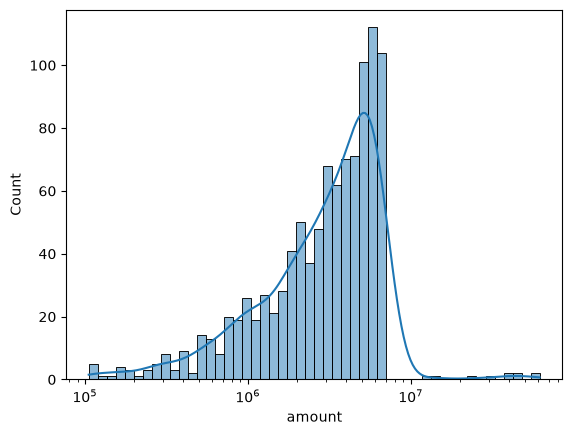

In [17]:
# We wanna see distributions of transaction amount
import seaborn as sns, matplotlib.pyplot as plt

sns.histplot(data=df, x='amount', bins=50, kde=True, log_scale=True)


In [18]:
# Based on that histogram plot, we can see there're some transactions that have transacation amount > 10 M
df[df['amount'] > 1e7].value_counts()

user_id  transaction_date  amount  
60       2025-03-24        43316140    1
70       2025-04-02        12997280    1
116      2025-01-31        30561560    1
127      2025-02-17        56455010    1
135      2025-03-14        41138800    1
159      2025-02-25        46437580    1
179      2025-03-19        14099890    1
196      2025-02-16        23853620    1
235      2025-01-06        38513870    1
237      2025-02-08        61709280    1
Name: count, dtype: int64

In [26]:
print(f"Minimun amount of transaction: {min(df['amount'])}")
print(f"Maximum amount of transaction: {max(df['amount'])}")

Minimun amount of transaction: 105435
Maximum amount of transaction: 61709280


In [25]:
# number of transaction with nominal hundreds of thousands (below millions)
df[df['amount'] < 1e6].count()

user_id             136
transaction_date    136
amount              136
dtype: int64

In [24]:
# number of transaction with nominal millions
df[(df['amount'] >= 1e6) & (df['amount'] < 1e7)].count()

user_id             868
transaction_date    868
amount              868
dtype: int64

In [27]:
# number of transactions with nominal over tens of millions
df[df['amount'] > 1e7].count()

user_id             10
transaction_date    10
amount              10
dtype: int64

In [29]:
df[df['user_id'].isin([60, 70, 116, 127, 135, 159, 179, 196, 235, 237])]

,user_id,transaction_date,amount
258,60,2025-03-09,4246118
259,60,2025-04-10,5526967
260,60,2025-04-02,974506
261,60,2025-02-26,3576808
262,60,2025-01-13,3457707
263,60,2025-01-23,943810
264,60,2025-03-24,43316140
290,70,2025-03-02,4394329
291,70,2025-04-02,12997280
292,70,2025-01-30,1643992


In [32]:
# We try to compare avg_transaction_amount in these user_id that one of the value has over 1e7 M
# And the result of avg_transaction_amount are different with avg_transaction_amount from status.csv
# Because of that we conclude that the amount of transactions in transactions.csv must divide by 10 (look on user_id 237)

df_filtered = df[df['user_id'].isin([60, 70, 116, 127, 135, 159, 179, 196, 235, 237])]

df_filtered.groupby('user_id')['amount'].mean().reset_index()

,user_id,amount
0,60,8.863151e+06
1,70,5.354309e+06
2,116,8.048695e+06
3,127,1.236969e+07
4,135,1.061675e+07
5,159,9.831332e+06
6,179,5.045878e+06
7,196,6.662548e+06
8,235,8.110915e+06
9,237,6.170928e+07


In [33]:
trx = df.copy()
trx["invalid_amount"] = (trx["amount"] > 1e7).astype(int)
trx["amount_clean"] = np.where(trx["invalid_amount"] == 1, trx["amount"]/10, trx["amount"])
trx["transaction_date"] = pd.to_datetime(trx["transaction_date"])

In [34]:
trx.info()

<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           1014 non-null   int64         
 1   transaction_date  1014 non-null   datetime64[us]
 2   amount            1014 non-null   int64         
 3   invalid_amount    1014 non-null   int64         
 4   amount_clean      1014 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(3)
memory usage: 39.7 KB


In [35]:
# Now the average amount from those user_id already equal with avg_transaction_amount status.csv

trx_filtered = trx[trx['user_id'].isin([60, 70, 116, 127, 135, 159, 179, 196, 235, 237])]

trx_filtered.groupby('user_id')['amount_clean'].mean().reset_index()

,user_id,amount_clean
0,60,3.293933e+06
1,70,2.429921e+06
2,116,4.119352e+06
3,127,2.207785e+06
4,135,4.445928e+06
5,159,2.865694e+06
6,179,3.233035e+06
7,196,3.595654e+06
8,235,3.159132e+06
9,237,6.170928e+06


In [36]:
trx.to_csv("../data/clean/transactions_clean.csv", index=False)